# AeroTech — Classification de défauts sur pièces mécaniques

Projet réalisé dans le cadre de la **formation IA de DigitalCity**.


In [ ]:
%pip install -r requirements.txt

Projet Machine Learning : Classification d'Avaries et Maintenance Prédictive Aéroportuaire
1. Contexte Général du Projet
La société AeroTech Solutions gère l'inspection visuelle automatique des pièces mécaniques et des composants de turbines d'avions après chaque vol. Lors des contrôles de routine, des caméras haute résolution photographient les pièces pour identifier les anomalies (fissures, piqûres de corrosion, rayures ou usure).

Actuellement, l'inspection est réalisée manuellement par des techniciens qualifiés, ce qui prend du temps et crée des goulets d'étranglement lors des opérations de maintenance.

Votre équipe de Data Science est sollicitée pour développer un prototype d'IA capable de classifier automatiquement l'état des pièces mécaniques à partir de leurs images afin d'orienter immédiatement la pièce vers le bon atelier de réparation.

2. Le Jeu de Données : Casting Products for Quality Inspection
Pour ce projet, vous travaillerez sur le dataset public Casting Products for Quality Inspection (disponible sur Kaggle ou via TensorFlow Datasets / Téléchargement Direct).

Description : Le jeu de données contient des images en niveaux de gris/couleurs de pièces métalliques moulées.

Classes :

def_front : Pièce présentant un défaut de fabrication ou une avarie mécanique.

ok_front : Pièce conforme et sans défaut.

Particularités : Les défauts peuvent être très subtils (petites fissures, micro-trous) ou très marqués. De plus, la luminosité et l'orientation des pièces peuvent varier légèrement.


In [7]:
import os
from PIL import Image
import numpy as np

# 1. Spécifiez le chemin vers votre dossier principal

DATASET_PATH = os.path.join("product_image", "casting_data", "casting_data")

# 2. Paramètres de chargement
IMAGE_SIZE = (128,128)  # Dimensions (Largeur, Hauteur)
LABELS = {'ok_front': 0, 'def_front': 1}  # Encodage numérique des classes

def load_data_from_directory(base_path, split_type):
    """
    Parcourt le dossier (train ou test) et retourne les images (X) et les labels (y)
    en utilisant Pillow (PIL).
    """
    X = []
    y = []
    
    split_dir = os.path.join(base_path, split_type)
    
    for label_name, label_code in LABELS.items():
        folder_path = os.path.join(split_dir, label_name)
        
        if not os.path.exists(folder_path):
            print(f"Attention : Le dossier {folder_path} n'existe pas.")
            continue
            
        print(f"Chargement des images du dossier : {label_name} ({split_type})...")
        
        for img_name in os.listdir(folder_path):
            img_path = os.path.join(folder_path, img_name)
            
            try:
                # Charger l'image avec PIL
                with Image.open(img_path) as img:
                    # S'assurer de la conversion en RGB (3 canaux)
                    img = img.convert('RGB')
                    
                    # Redimensionner l'image (PIL utilise le format tuple (largeur, hauteur))
                    img = img.resize(IMAGE_SIZE)
                    
                    # Convertir l'image PIL en tableau NumPy
                    img_array = np.array(img)
                    
                    X.append(img_array)
                    y.append(label_code)
                    
            except (IOError, SyntaxError):
                # Permet d'ignorer les éventuels fichiers corrompus ou non-images
                continue
                
    # Conversion globale en tableaux NumPy et normalisation des pixels [0, 1]
    X = np.array(X, dtype='float32') / 255.0
    y = np.array(y, dtype='int32')
    
    return X, y

# 3. Chargement effectif des jeux d'entraînement et de test
print("=== DÉBUT DU CHARGEMENT DES DONNÉES ===")
X_train, y_train = load_data_from_directory(DATASET_PATH, 'train')
X_test, y_test = load_data_from_directory(DATASET_PATH, 'test')

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

=== DÉBUT DU CHARGEMENT DES DONNÉES ===
Chargement des images du dossier : ok_front (train)...
Chargement des images du dossier : def_front (train)...
Chargement des images du dossier : ok_front (test)...
Chargement des images du dossier : def_front (test)...
X_train : (6633, 128, 128, 3)
X_test  : (715, 128, 128, 3)


3. Objectifs et Périmètre du Projet
Votre objectif est de concevoir, entraîner et évaluer un modèle de Deep Learning performant pour automatiser ce diagnostic.

Attentes principales :
Exploration et Préparation des données :

Inspecter le volume de données disponible, la répartition des classes et la résolution des images.

Mettre en place un découpage adéquat des données (Entraînement / Validation / Test).

Modélisation & Expérimentations :

Développer une première baseline (modèle simple) pour établir une métrique de référence.

Concevoir un ou plusieurs réseaux de neurones profonds (CNN personnalisés ou architectures pré-entraînées via Transfer Learning).

Explorer différentes stratégies d'apprentissage :

Évaluer l'impact du prétraitement des images (redimensionnement, normalisation).

Tester l'impact de la Data Augmentation (rotation, zoom, variation de contraste, flous) : Permet-elle de limiter le surapprentissage (overfitting) et d'améliorer la robustesse du modèle ?

Évaluation & Analyse des Résultats :

Présenter les métriques de performance globales (Accuracy, Precision, Recall, F1-score, Matrice de confusion).

Analyser spécifiquement les faux négatifs (pièces défectueuses classées comme "OK") : quelles sont les conséquences industrielles de ce type d'erreur ?

Visualiser quelques cas d'erreurs de prédiction pour comprendre les limites actuelles de votre modèle.

Classes : [0 1] | NB : [2875 3758]
Pourcent de défauts : 56.7 %


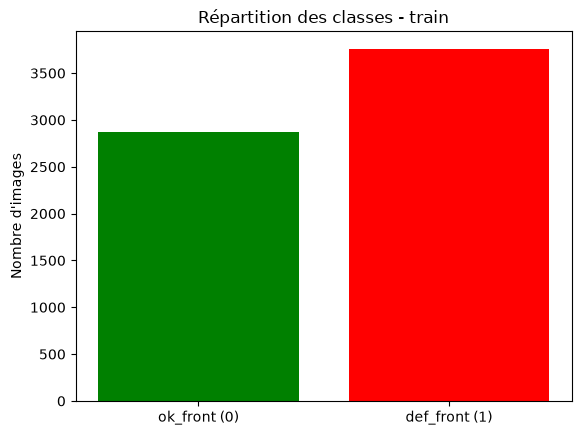

Classes : [0 1] | NB : [262 453]
Pourcent de défauts : 63.4 %


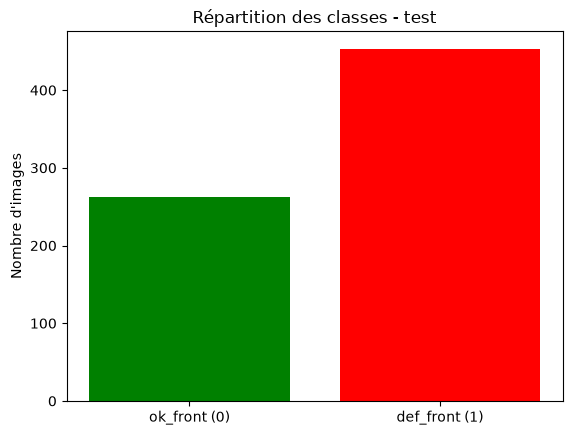

In [14]:
import matplotlib.pyplot as plt

# y_train
classes, nb = np.unique(y_train, return_counts=True)
print("Classes :", classes, "| NB :", nb)
print("Pourcent de défauts :", round(nb[1] / nb.sum() * 100, 1), "%")

plt.bar(["ok_front (0)", "def_front (1)"], nb, color=["green", "red"])
plt.title("Répartition des classes - train")
plt.ylabel("Nombre d'images")
plt.show()

# y_test
classes, nb = np.unique(y_test, return_counts=True)
print("Classes :", classes, "| NB :", nb)
print("Pourcent de défauts :", round(nb[1] / nb.sum() * 100, 1), "%")

plt.bar(["ok_front (0)", "def_front (1)"], nb, color=["green", "red"])
plt.title("Répartition des classes - test")
plt.ylabel("Nombre d'images")
plt.show()

Taille d'origine : (300, 300)
couleur : RGB
Tailles différentes trouvées : {(300, 300)}


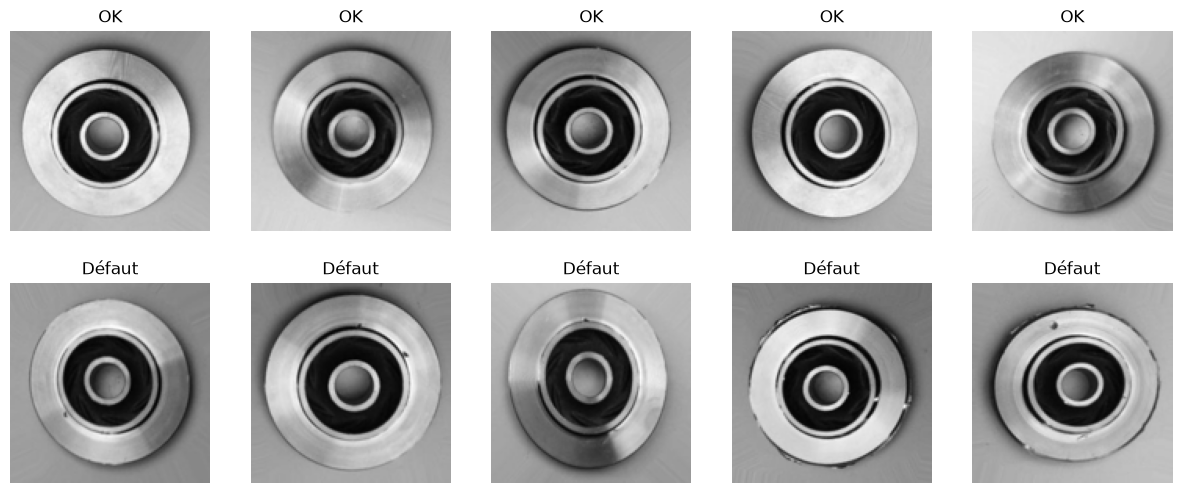

In [15]:
dossier = os.path.join(DATASET_PATH, "train", "ok_front")
premier_fichier = os.listdir(dossier)[0]

img = Image.open(os.path.join(dossier, premier_fichier))
print("Taille d'origine :", img.size)
print("couleur :", img.mode)


tailles = set()
for split in ["train", "test"]:
    for classe in LABELS:
        dossier_classe = os.path.join(DATASET_PATH, split, classe)
        for nom in os.listdir(dossier_classe):
            with Image.open(os.path.join(dossier_classe, nom)) as im:
                tailles.add(im.size)
print("Tailles différentes trouvées :", tailles)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
idx_ok = np.where(y_train == 0)[0][:5]
idx_def = np.where(y_train == 1)[0][:5]

for col in range(5):
    axes[0, col].imshow(X_train[idx_ok[col]])
    axes[0, col].set_title("OK")
    axes[0, col].axis("off")
    axes[1, col].imshow(X_train[idx_def[col]])
    axes[1, col].set_title("Défaut")
    axes[1, col].axis("off")

plt.show()

In [16]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

print("Train      :", X_tr.shape, "| % défauts :", round(y_tr.mean() * 100, 1))
print("Validation :", X_val.shape, "| % défauts :", round(y_val.mean() * 100, 1))
print("Test       :", X_test.shape, "| % défauts :", round(y_test.mean() * 100, 1))

Train      : (5306, 128, 128, 3) | % défauts : 56.7
Validation : (1327, 128, 128, 3) | % défauts : 56.7
Test       : (715, 128, 128, 3) | % défauts : 63.4


### Conclusion du découpage

- Le jeu de **test d'origine est conservé intact** : il ne servira qu'à l'évaluation finale, pour obtenir un score sans biais.
- **20 % du train** sert de jeu de validation. Le découpage est **stratifié** (`stratify=y_train`), donc le train et la validation ont exactement la même proportion de défauts (**56,7 %**).
- Répartition finale : **5 306** images d'entraînement / **1 327** de validation / **715** de test.
- `random_state=42` fixe le hasard : le découpage est identique à chaque exécution, ce qui rend les comparaisons entre modèles fiables.

## 3. Baseline (modèle simple)

Objectif : obtenir un **score de référence** que les modèles plus complexes (CNN, Transfer Learning) devront battre.

- **Dummy** : prédit toujours la classe la plus fréquente, sans regarder l'image → score plancher.
- **Régression logistique** : modèle linéaire simple sur les pixels.

Un modèle scikit-learn attend un tableau 2D (une ligne par image). Les images sont donc passées en niveaux de gris, réduites en 32×32 puis aplaties en 1 024 valeurs.

In [17]:
def prep_sklearn(X):
    X_gris = X.mean(axis=3)
    X_petit = X_gris[:, ::4, ::4]
    return X_petit.reshape(len(X), -1)

X_tr_plat = prep_sklearn(X_tr)
X_val_plat = prep_sklearn(X_val)
print("Avant :", X_tr.shape, "-> Après :", X_tr_plat.shape)

Avant : (5306, 128, 128, 3) -> Après : (5306, 1024)


In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

#B1
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_tr_plat, y_tr)
pred_dummy = dummy.predict(X_val_plat)

#B2
logreg = LogisticRegression(max_iter=2000)
logreg.fit(X_tr_plat, y_tr)
pred_logreg = logreg.predict(X_val_plat)

print("Accuracy log :", round(accuracy_score(y_val, pred_logreg), 4))
print("Accuracy dummy  :", round(accuracy_score(y_val, pred_dummy), 3))
print("Accuracy logreg :", round(accuracy_score(y_val, pred_logreg), 3))
print()
print(classification_report(y_val, pred_logreg, target_names=["ok_front", "def_front"]))

Accuracy dummy  : 0.567
Accuracy logreg : 0.902

              precision    recall  f1-score   support

    ok_front       0.88      0.89      0.89       575
   def_front       0.92      0.91      0.91       752

    accuracy                           0.90      1327
   macro avg       0.90      0.90      0.90      1327
weighted avg       0.90      0.90      0.90      1327



## 4. CNN personnalisé

In [23]:
from tensorflow import keras
from tensorflow.keras import layers

cnn = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall")]
)

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

hist_cnn = cnn.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 35s 204ms/step - accuracy: 0.6234 - loss: 0.6159 - precision: 0.6385 - recall: 0.7731 - val_accuracy: 0.7016 - val_loss: 0.4937 - val_precision: 0.9890 - val_recall: 0.4787
Epoch 2/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 32s 194ms/step - accuracy: 0.8562 - loss: 0.3285 - precision: 0.8839 - recall: 0.8589 - val_accuracy: 0.9488 - val_loss: 0.1411 - val_precision: 0.9817 - val_recall: 0.9269
Epoch 3/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 32s 195ms/step - accuracy: 0.9363 - loss: 0.1630 - precision: 0.9544 - recall: 0.9321 - val_accuracy: 0.9050 - val_loss: 0.1934 - val_precision: 1.0000 - val_recall: 0.8324
Epoch 4/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 33s 197ms/step - accuracy: 0.9529 - loss: 0.1269 - precision: 0.9649 - recall: 0.9514 - val_accuracy: 0.9872 - val_loss: 0.0585 - val_precision: 0.9973 - val_recall: 0.9801
Epoch 5/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 32s 193ms/step - accuracy: 0.9732 - loss: 0.0818 - precision: 0.9841 - recall: 0.9684 - val_accuracy: 0.9887

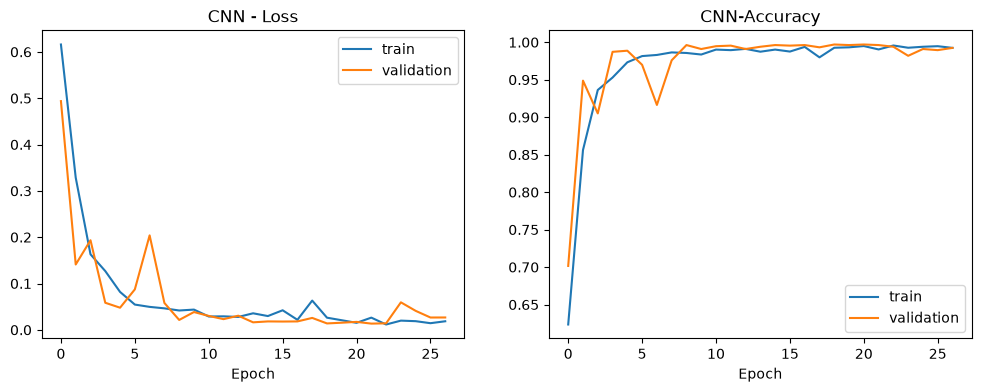

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(hist_cnn.history["loss"], label="train")
ax[0].plot(hist_cnn.history["val_loss"], label="validation")
ax[0].set_title("CNN - Loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(hist_cnn.history["accuracy"], label="train")
ax[1].plot(hist_cnn.history["val_accuracy"], label="validation")
ax[1].set_title("CNN-Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.show()

In [28]:
proba_val = cnn.predict(X_val).ravel()
pred_cnn = (proba_val > 0.5).astype(int)

print("Accuracy baseline :", round(accuracy_score(y_val, pred_logreg), 3))
print("Accuracy CNN      :", round(accuracy_score(y_val, pred_cnn), 3))
print()
print(classification_report(y_val, pred_cnn, target_names=["ok_front", "def_front"]))

42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step
Accuracy baseline : 0.902
Accuracy CNN      : 0.996

              precision    recall  f1-score   support

    ok_front       0.99      1.00      1.00       575
   def_front       1.00      0.99      1.00       752

    accuracy                           1.00      1327
   macro avg       1.00      1.00      1.00      1327
weighted avg       1.00      1.00      1.00      1327



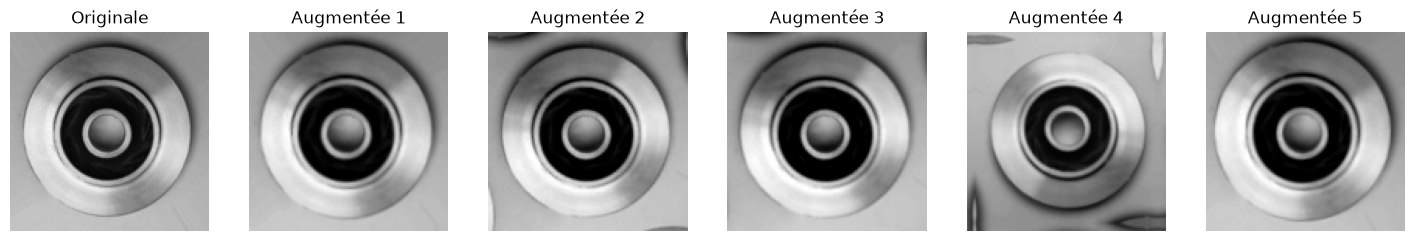

In [31]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2),
])
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(X_tr[0])
axes[0].set_title("Originale")
axes[0].axis("off")

for col in range(1, 6):
    img_aug = augmentation(X_tr[:1], training=True)[0]
    axes[col].imshow(np.clip(img_aug, 0, 1))
    axes[col].set_title(f"Augmentée {col}")
    axes[col].axis("off")

plt.show()

In [33]:
cnn_aug = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    augmentation,

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

cnn_aug.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall")]
)

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

hist_aug = cnn_aug.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 43s 245ms/step - accuracy: 0.6364 - loss: 0.6305 - precision: 0.6468 - recall: 0.7894 - val_accuracy: 0.7747 - val_loss: 0.5207 - val_precision: 0.8124 - val_recall: 0.7832
Epoch 2/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 37s 224ms/step - accuracy: 0.7495 - loss: 0.5126 - precision: 0.7757 - recall: 0.7848 - val_accuracy: 0.8425 - val_loss: 0.3636 - val_precision: 0.9458 - val_recall: 0.7660
Epoch 3/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 39s 235ms/step - accuracy: 0.8334 - loss: 0.3727 - precision: 0.8506 - recall: 0.8563 - val_accuracy: 0.7837 - val_loss: 0.4048 - val_precision: 0.9735 - val_recall: 0.6356
Epoch 4/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 35s 212ms/step - accuracy: 0.8801 - loss: 0.2844 - precision: 0.9047 - recall: 0.8812 - val_accuracy: 0.9005 - val_loss: 0.2153 - val_precision: 0.9905 - val_recall: 0.8324
Epoch 5/30
166/166 ━━━━━━━━━━━━━━━━━━━━ 36s 214ms/step - accuracy: 0.9110 - loss: 0.2252 - precision: 0.9307 - recall: 0.9108 - val_accuracy: 0.9209

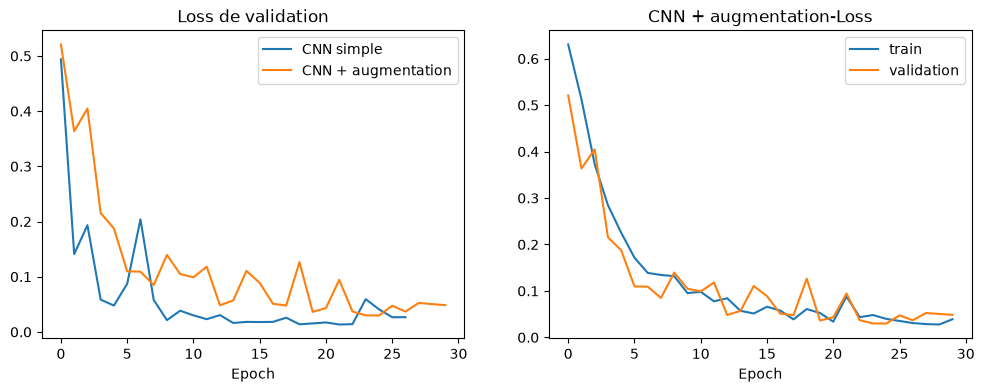

42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step
Accuracy baseline       : 0.902
Accuracy CNN            : 0.996
Accuracy CNN + augment. : 0.992

              precision    recall  f1-score   support

    ok_front       0.98      1.00      0.99       575
   def_front       1.00      0.99      0.99       752

    accuracy                           0.99      1327
   macro avg       0.99      0.99      0.99      1327
weighted avg       0.99      0.99      0.99      1327



In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(hist_cnn.history["val_loss"], label="CNN simple")
ax[0].plot(hist_aug.history["val_loss"], label="CNN + augmentation")
ax[0].set_title("Loss de validation")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(hist_aug.history["loss"], label="train")
ax[1].plot(hist_aug.history["val_loss"], label="validation")
ax[1].set_title("CNN + augmentation-Loss")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.show()

proba_val_aug = cnn_aug.predict(X_val).ravel()
pred_aug = (proba_val_aug > 0.5).astype(int)

print("Accuracy baseline       :", round(accuracy_score(y_val, pred_logreg), 3))
print("Accuracy CNN            :", round(accuracy_score(y_val, pred_cnn), 3))
print("Accuracy CNN + augment. :", round(accuracy_score(y_val, pred_aug), 3))
print()
print(classification_report(y_val, pred_aug, target_names=["ok_front", "def_front"]))

### Conclusion sur la Data Augmentation

- Les deux CNN battent largement la baseline (**0,902**) : **0,996** sans augmentation, **0,992** avec.
- L'augmentation **n'améliore pas** le score ici : la loss de validation est plus irrégulière et le modèle converge plus lentement (l'EarlyStopping ne s'est pas déclenché avant 30 epochs).
- Avec l'augmentation, la loss de train reste **au même niveau que la loss de validation** : le modèle ne sur-apprend pas. Mais le CNN simple ne sur-apprenait déjà presque pas (Dropout + EarlyStopping), donc l'augmentation avait peu de marge pour aider.
- Les images du dataset sont très homogènes (même éclairage, même cadrage, vue de dessus). En production, si les conditions de prise de vue changent (autre caméra, pièce tournée, lumière différente), l'augmentation rendrait le modèle plus **robuste**, même si le score de validation ne le montre pas ici.

**Modèle retenu : le CNN simple** (meilleure loss et meilleure accuracy de validation).

## 5. Évaluation finale sur le jeu de test

Le jeu de test n'a servi à aucun choix jusqu'ici : c'est le score qu'on peut annoncer pour le modèle en conditions réelles.

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step 
Accuracy  : 1.0
Precision : 1.0
Recall    : 1.0
F1-score  : 1.0

              precision    recall  f1-score   support

    ok_front       1.00      1.00      1.00       262
   def_front       1.00      1.00      1.00       453

    accuracy                           1.00       715
   macro avg       1.00      1.00      1.00       715
weighted avg       1.00      1.00      1.00       715



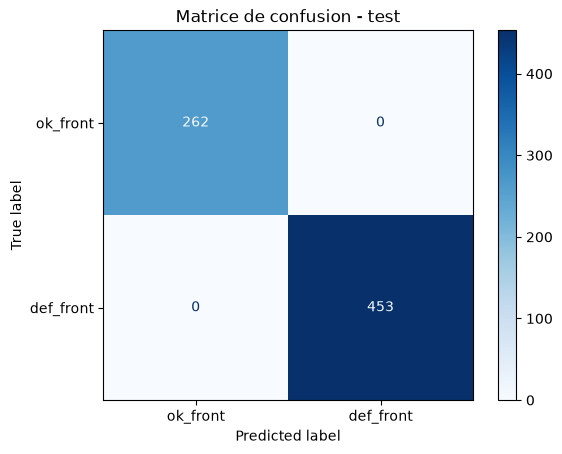

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score

proba_test = cnn.predict(X_test).ravel()
pred_test = (proba_test > 0.5).astype(int)

print("Accuracy  :", round(accuracy_score(y_test, pred_test), 3))
print("Precision :", round(precision_score(y_test, pred_test), 3))
print("Recall    :", round(recall_score(y_test, pred_test), 3))
print("F1-score  :", round(f1_score(y_test, pred_test), 3))
print()
print(classification_report(y_test, pred_test, target_names=["ok_front", "def_front"]))

cm = confusion_matrix(y_test, pred_test)
ConfusionMatrixDisplay(cm, display_labels=["ok_front", "def_front"]).plot(cmap="Blues")
plt.title("Matrice de confusion - test")
plt.show()

Faux négatifs test : 0
Faux positifs test : 0


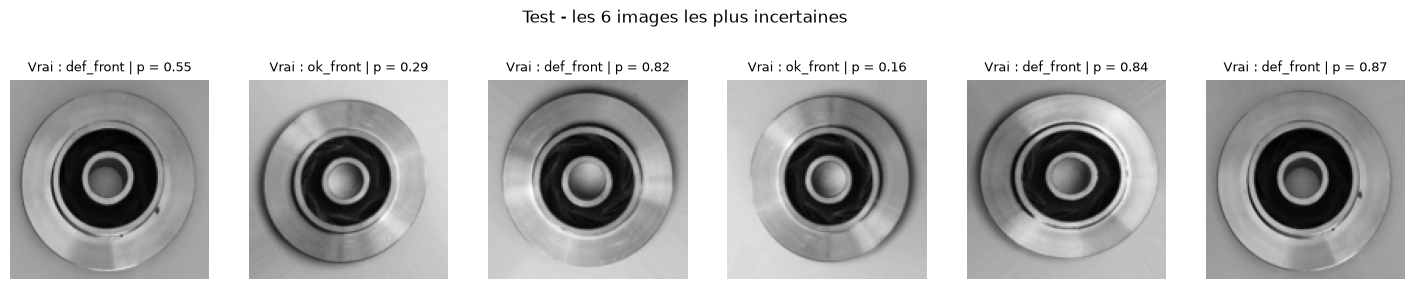

Faux négatifs validation : 4
Faux positifs validation : 1


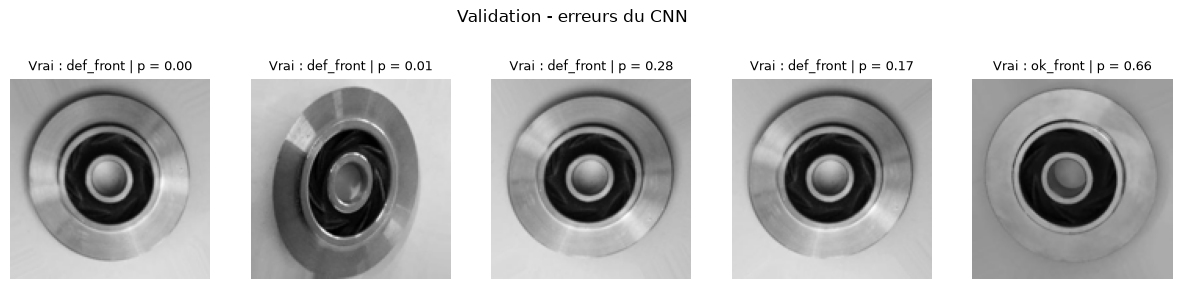

In [40]:
def afficher(X, y, proba, indices, titre):
    fig, axes = plt.subplots(1, len(indices), figsize=(3 * len(indices), 3.5), squeeze=False)
    for col, i in enumerate(indices):
        vrai = "def_front" if y[i] == 1 else "ok_front"
        axes[0, col].imshow(X[i])
        axes[0, col].set_title(f"Vrai : {vrai} | p = {proba[i]:.2f}", fontsize=9)
        axes[0, col].axis("off")
    fig.suptitle(titre)
    plt.show()


print("Faux négatifs test :", ((y_test == 1) & (pred_test == 0)).sum())
print("Faux positifs test :", ((y_test == 0) & (pred_test == 1)).sum())
hesitants = np.argsort(np.abs(proba_test - 0.5))[:6]
afficher(X_test, y_test, proba_test, hesitants, "Test - les 6 images les plus incertaines")


faux_neg_val = np.where((y_val == 1) & (pred_cnn == 0))[0]
faux_pos_val = np.where((y_val == 0) & (pred_cnn == 1))[0]
print("Faux négatifs validation :", len(faux_neg_val))
print("Faux positifs validation :", len(faux_pos_val))
erreurs_val = list(faux_neg_val) + list(faux_pos_val)
afficher(X_val, y_val, proba_val, erreurs_val, "Validation - erreurs du CNN")

In [39]:

for seuil in [0.5, 0.3, 0.1, 0.01]:
    pred = (proba_val > seuil).astype(int)
    fn = ((y_val == 1) & (pred == 0)).sum()
    fp = ((y_val == 0) & (pred == 1)).sum()
    print(f"Seuil {seuil} -> faux négatifs : {fn} | faux positifs : {fp} | recall défauts : {recall_score(y_val, pred):.3f}")

Seuil 0.5 -> faux négatifs : 4 | faux positifs : 1 | recall défauts : 0.995
Seuil 0.3 -> faux négatifs : 4 | faux positifs : 1 | recall défauts : 0.995
Seuil 0.1 -> faux négatifs : 2 | faux positifs : 7 | recall défauts : 0.997
Seuil 0.01 -> faux négatifs : 1 | faux positifs : 39 | recall défauts : 0.999


### Analyse des résultats et des faux négatifs

**Score sur le test** : accuracy, precision, recall et F1 à **1,00**. La matrice de confusion ne montre **aucune erreur** sur les 715 images (262 OK, 453 défauts).

**Pourquoi les faux négatifs sont l'erreur la plus grave**
- Un **faux positif** (pièce OK classée défaut) coûte peu : un technicien revérifie la pièce ou elle est écartée pour rien.
- Un **faux négatif** (pièce défectueuse classée OK) laisse partir une pièce avec une fissure ou de la corrosion vers le moteur. En aéronautique, cela peut mener à une casse en vol, un arrêt de l'avion (AOG), des coûts très élevés et surtout un **risque pour la sécurité**.
- La métrique à surveiller en priorité est donc le **recall de la classe `def_front`**, plus que l'accuracy.

**Limites observées**
- Le 100 % du test ne veut pas dire que le modèle est parfait : sur la validation, il fait encore **4 faux négatifs** et 1 faux positif sur 1 327 images.
- Deux de ces faux négatifs ont une probabilité proche de **0** : le modèle se trompe **avec certitude**. Les défauts sont très petits (petite piqûre ou bavure sur le bord) et, réduits à 128×128, ils ne font plus que quelques pixels. Une pièce est aussi tournée et décentrée, un cadrage rare dans le dataset.
- Sur le test, les images les plus incertaines sont aussi des défauts discrets proches du bord (p = 0,55 pour la plus hésitante).

**Réglage du seuil**
- Baisser le seuil de 0,5 à **0,1** fait passer les faux négatifs de 4 à **2**, pour 7 faux positifs au lieu de 1. C'est un bon compromis dans un contexte où rater un défaut coûte beaucoup plus cher qu'une vérification en trop.
- Descendre jusqu'à 0,01 ne supprime pas le dernier faux négatif et génère 39 faux positifs : certains défauts sont invisibles pour le modèle quel que soit le seuil.

## 6. Conclusion

| Modèle | Accuracy validation |
|---|---|
| Dummy (classe majoritaire) | 0,567 |
| Régression logistique | 0,902 |
| CNN + augmentation | 0,992 |
| **CNN simple (retenu)** | **0,996** (test : **1,00**) |

- Un CNN simple à 3 couches de convolution suffit à automatiser le diagnostic avec un très haut niveau de fiabilité, bien au-delà de la baseline linéaire.
- La Data Augmentation n'a pas amélioré le score sur ce dataset très homogène, mais elle reste intéressante pour la robustesse en conditions réelles.
- Pour un déploiement, on recommande :
  - un **seuil abaissé (~0,1)** pour limiter les faux négatifs ;
  - de faire **revérifier par un technicien** les pièces dont la probabilité est incertaine (par exemple entre 0,1 et 0,9), plutôt que de supprimer l'inspection humaine ;
  - d'essayer une **résolution plus grande** (ex. 256×256 ou 300×300) pour que les petits défauts restent visibles, ou un modèle pré-entraîné (**Transfer Learning**) ;
  - d'**enrichir le dataset** avec plus d'exemples de petits défauts et de pièces mal cadrées.